<a href="https://colab.research.google.com/github/Breif7/LifeOS/blob/main/LifeOS_ML_EVM_Sprint_Tracker_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sistema Cognitivo LifeOS-ML
## Planificación por Sprints Quincenales, Control Presupuestal y Gestión del Valor Ganado (EVM) con Machine Learning Aplicado

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/breif7/LifeOS/blob/main/LifeOS_ML_EVM_Sprint_Tracker_Colab.ipynb)

**Código de Proyecto:** `PRJ-LIFEOS-ML-2026-Q4`  
**Autor y Director:** Ing. Miguel Martínez Ortega (Ingeniero en Nanotecnología · Maestría en Inteligencia Artificial, UNIR)  
**Marco Metodológico:** Híbrido: Línea Base Predictiva (PMBOK® 6ª y 7ª Ed., EDT/WBS, CPM/PERT, EVM) + Ejecución Ágil (Scrum Quincenal + Kanban WIP=3)  
**Propósito:** Portafolio Técnico Demostrativo para roles de **Machine Learning Engineer / AI Tech Lead**.

---
### Resumen de la Triple Restricción:
- **Alcance (Scope):** 16 paquetes de trabajo en 5 fases, motor CPM/PERT, clasificador NLP supervisado (Matriz de Covey), control EVM dual y predictor Regresión Polinomial Ridge L2.
- **Tiempo (Schedule):** 12 semanas (6 Sprints Quincenales de 15 días / 10 días hábiles) sincronizados con dispersión de nómina. Presupuesto de esfuerzo $BAC = 240.0$ horas.
- **Coste (Budget):** Ingreso quincenal $\$14,691.00$ MXN. Línea base operativa $BAC = \$10,900.00$ MXN/quincena ($\$65,400.00$ MXN en 6Q). Reserva de amortización/liquidez: $\$3,791.00$ MXN/quincena. Tope diario discrecional: $\$300.00$ MXN.
- **Calidad (Quality):** F1-Score macro $> 0.85$ en NLP, exactitud CV 4-Fold $> 95.0%$, error EVM $< 3%$, y $0.00$ pesos en intereses moratorios bancarios (CAT 0%).


---
## 0. Configuración del Entorno y Dependencias
Instalamos e importamos las librerías necesarias. Si se ejecuta en Google Colab, se clona automáticamente el repositorio de GitHub para tener acceso a los módulos locales y la suite de pruebas.


In [1]:
# 1. Detección de Google Colab y sincronización del repositorio
import os
import sys
try:
    import google.colab
    is_colab = True
except ImportError:
    is_colab = False

if is_colab:
    if not os.path.exists('lifeos'):
        !git clone https://github.com/breif7/LifeOS.git
        if os.path.exists('LifeOS'):
            %cd LifeOS
    if '.' not in sys.path:
        sys.path.insert(0, '.')

# 2. Instalación de dependencias
!pip install -q matplotlib pandas numpy pytest

import math
import re
from copy import deepcopy
from dataclasses import dataclass, field
from typing import Dict, List, Optional, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Configuración estética de gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
print('Entorno de ejecución inicializado con éxito.')


Cloning into 'LifeOS'...
remote: Enumerating objects: 25, done.
remote: Counting objects: 100% (25/25), done.
remote: Compressing objects: 100% (23/23), done.
remote: Total 25 (delta 1), reused 25 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (25/25), 768.90 KiB | 9.26 MiB/s, done.
Resolving deltas: 100% (1/1), done.
/content/LifeOS
Entorno de ejecución inicializado con éxito.


---
## 1. Línea Base de Gobernanza y WBS (16 Paquetes de Trabajo)
Estructuramos los 16 paquetes de trabajo terminales según la Tabla 2 del Plan de Gestión del Proyecto (PGP).


In [2]:
from lifeos.config import WBS_CATALOG, CREDIT_CARDS, RISK_CATALOG, BAC_HOURS, TOTAL_BAC_FINANCIAL
from lifeos.cpm_pert import CPMNetwork

# Instanciamos la red y calculamos la programación temprana y tardía
cpm_net = CPMNetwork()
packages = cpm_net.compute_schedule()
summary_table = cpm_net.get_summary_table()

df_wbs = pd.DataFrame(summary_table)
display_cols = ['wbs_id', 'name', 'sprint', 'duration', 'bac_cost', 'predecessors', 'es', 'ef', 'ls', 'lf', 'slack', 'pert_te', 'is_critical']
print(f'Presupuesto hasta la Conclusión en Esfuerzo (BAC): {BAC_HOURS:.1f} horas')


Presupuesto hasta la Conclusión en Esfuerzo (BAC): 240.0 horas


In [3]:
# Mostramos la tabla completa de planificación
pd.set_option('display.max_columns', 15)
pd.set_option('display.width', 1000)
df_wbs[display_cols]


,wbs_id,name,sprint,duration,bac_cost,predecessors,es,ef,ls,lf,slack,pert_te,is_critical
0,1.1,"Definición de URD, Win Conditions y Acta Kick-off",S1,10.0,2500.0,-,0.0,10.0,0.0,10.0,0.0,10.33,SÍ
1,1.2,Auditoría de Tarjetas y Línea Base Financiera,S1,12.0,3000.0,1.1,10.0,22.0,10.0,22.0,0.0,12.33,SÍ
2,1.3,Diseño del PGP Maestro y Matriz de Riesgos,S1,14.0,3500.0,1.1,10.0,24.0,16.0,30.0,6.0,14.33,No
3,2.1,Pipeline ETL de Estados de Cuenta y Captura Qu...,S2,18.0,4800.0,1.2,22.0,40.0,22.0,40.0,0.0,18.33,SÍ
4,2.2,Alertas de Pago Cero Intereses (CAT 0%) y Tope...,S2,14.0,3800.0,2.1,40.0,54.0,62.0,76.0,22.0,14.33,No
5,2.3,Sincronización Sprints con Maestría UNIR y Háb...,S2,10.0,2800.0,1.3,24.0,34.0,30.0,40.0,6.0,10.33,No
6,3.1,Curación de Corpus Bilingüe Finanzas y Tareas IA,S3,16.0,4500.0,"2.1, 2.3",40.0,56.0,40.0,56.0,0.0,16.33,SÍ
7,3.2,Entrenamiento Clasificador NLP (TF-IDF + Softm...,S3,20.0,5600.0,3.1,56.0,76.0,56.0,76.0,0.0,20.67,SÍ
8,3.3,Motor Predictivo Burn-Rate y EVM (Regresión Po...,S4,22.0,6200.0,"2.2, 3.2",76.0,98.0,76.0,98.0,0.0,22.67,SÍ
9,4.1,API REST FastAPI para Inferencia ML y Motor CPM,S4,20.0,5800.0,3.2,76.0,96.0,78.0,98.0,2.0,20.33,No


---
## 2. Motor Algorítmico CPM/PERT y Simulación de Monte Carlo
El análisis de la red de precedencias determina un **Camino Crítico determinista de 166.0 horas** y una **media PERT de 170.17 horas (± 3.79 h)**.  
Ejecutamos una **Simulación de Monte Carlo con 10,000 iteraciones** muestreando duraciones estocásticas bajo la distribución Beta-PERT.


In [4]:
# Ejecutar análisis PERT y Simulación Monte Carlo
pert_stats = cpm_net.get_pert_statistics()
print('Estadísticas de Ruta Crítica (PERT):', pert_stats)

mc_res = cpm_net.run_monte_carlo_simulation(iterations=10000, target_hours=255.0, random_seed=42)
print(f"Iteraciones: {mc_res['iterations']:,}")
print(f"Media simulada: {mc_res['mean_hours']} h | Desviación estándar: {mc_res['std_hours']} h")
print(f"Percentil 85 (P85): {mc_res['p85_hours']} h | Percentil 95 (P95): {mc_res['p95_hours']} h")
print(f"Probabilidad de éxito dentro de 255 h (BAC + 6% contingencia): {mc_res['prob_under_threshold']:.1f}%")


Estadísticas de Ruta Crítica (PERT): {'deterministic_cp_hours': 166.0, 'total_scope_hours': 240.0, 'pert_mean_cp_hours': 170.15, 'pert_std_cp_hours': 3.82, 'pert_var_cp': 14.6111}
Iteraciones: 10,000
Media simulada: 170.44 h | Desviación estándar: 4.15 h
Percentil 85 (P85): 174.77 h | Percentil 95 (P95): 177.38 h
Probabilidad de éxito dentro de 255 h (BAC + 6% contingencia): 100.0%


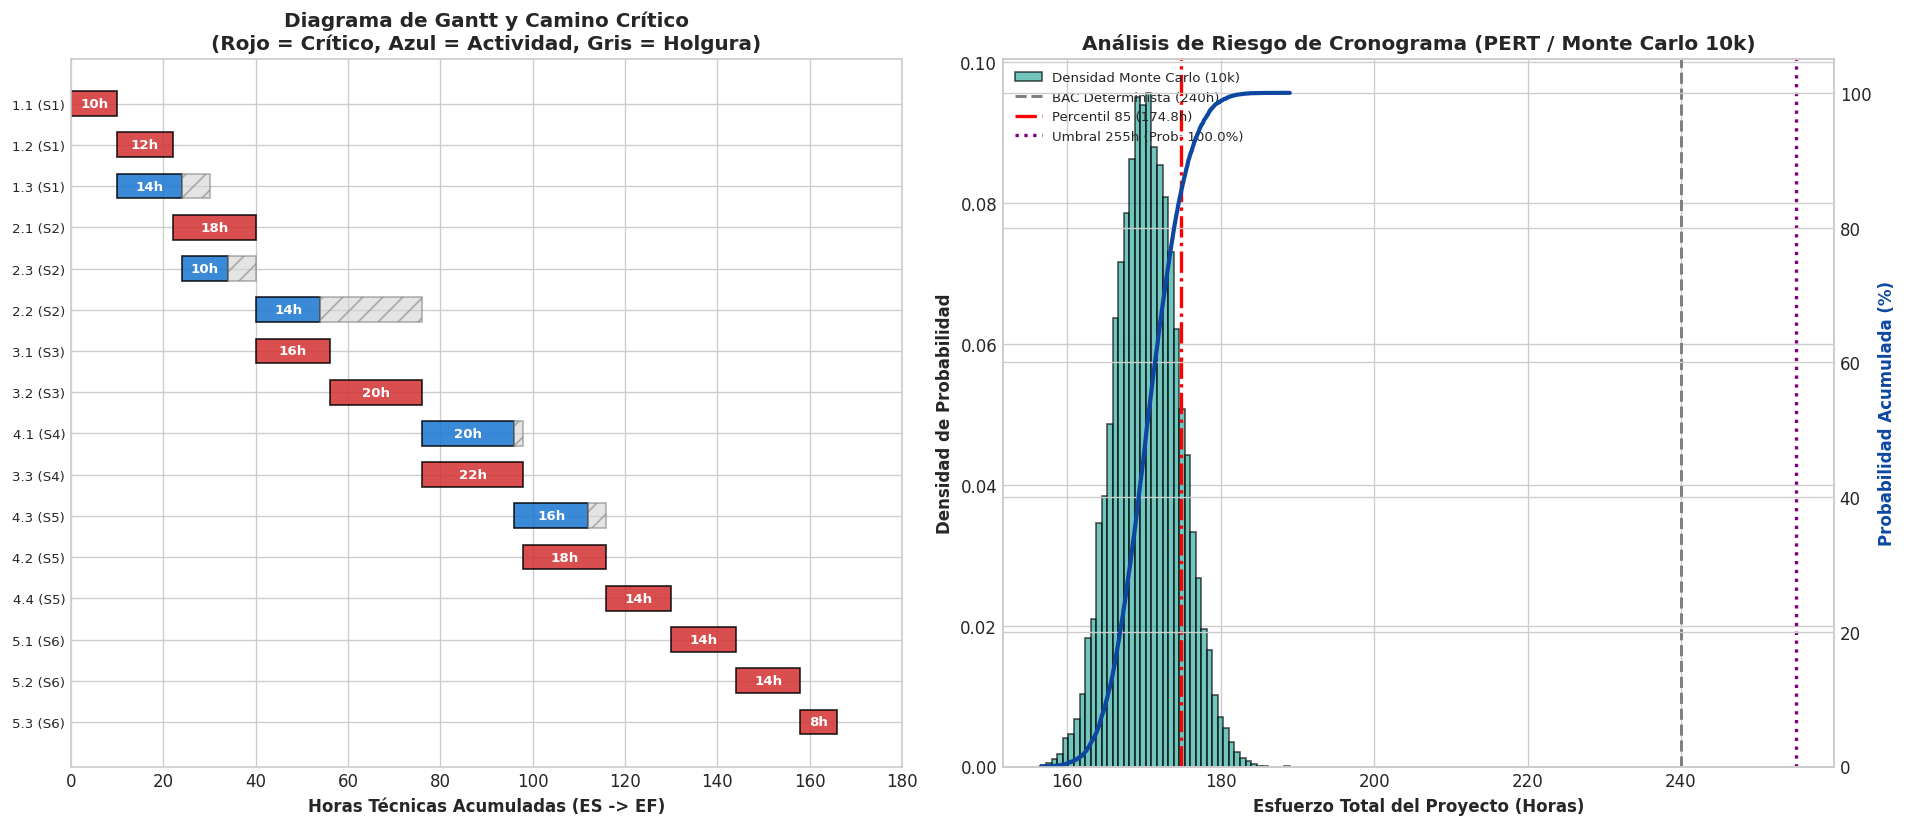

In [5]:
# Figura 1 del PGP: Diagrama de Gantt con Camino Crítico (izq) y Simulación Monte Carlo (der)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# --- Gráfico 1: Gantt con Camino Crítico ---
ordered_packages = list(packages.values())
ordered_packages.sort(key=lambda p: (p.es, p.ef), reverse=True)

y_labels = [f"{p.wbs_id} ({p.sprint})" for p in ordered_packages]
y_positions = np.arange(len(ordered_packages))

for idx, pkg in enumerate(ordered_packages):
    color = '#D32F2F' if pkg.is_critical else '#1976D2'  # Rojo si es crítico, Azul si no
    ax1.barh(idx, pkg.duration, left=pkg.es, color=color, alpha=0.85, edgecolor='black', height=0.6)
    if pkg.total_slack > 0:
        ax1.barh(idx, pkg.total_slack, left=pkg.ef, color='lightgray', hatch='//', alpha=0.6, edgecolor='gray', height=0.6)
    ax1.text(pkg.es + pkg.duration / 2, idx, f"{pkg.duration:.0f}h", ha='center', va='center', color='white', fontweight='bold', fontsize=8)

ax1.set_yticks(y_positions)
ax1.set_yticklabels(y_labels, fontsize=8)
ax1.set_xlabel('Horas Técnicas Acumuladas (ES -> EF)', fontweight='bold')
ax1.set_title('Diagrama de Gantt y Camino Crítico\n(Rojo = Crítico, Azul = Actividad, Gris = Holgura)', fontweight='bold')
ax1.set_xlim(0, 180)

# --- Gráfico 2: Simulación de Monte Carlo ---
sim_dur = mc_res['raw_simulations']
count, bins, ignored = ax2.hist(sim_dur, bins=45, density=True, color='#26A69A', alpha=0.65, edgecolor='black', label='Densidad Monte Carlo (10k)')

# Curva acumulada de probabilidad en segundo eje Y
ax2_cdf = ax2.twinx()
sorted_data = np.sort(sim_dur)
cdf = np.arange(len(sorted_data)) / float(len(sorted_data)) * 100.0
ax2_cdf.plot(sorted_data, cdf, color='#0D47A1', lw=2.5, label='Probabilidad de Éxito Acumulada (%)')
ax2_cdf.set_ylabel('Probabilidad Acumulada (%)', color='#0D47A1', fontweight='bold')
ax2_cdf.set_ylim(0, 105)

# Líneas de referencia
ax2.axvline(240.0, color='gray', linestyle='--', lw=1.8, label='BAC Determinista (240h)')
ax2.axvline(mc_res['p85_hours'], color='red', linestyle='-.', lw=2.0, label=f"Percentil 85 ({mc_res['p85_hours']:.1f}h)")
ax2.axvline(255.0, color='purple', linestyle=':', lw=2.0, label=f"Umbral 255h (Prob: {mc_res['prob_under_threshold']:.1f}%)")

ax2.set_xlabel('Esfuerzo Total del Proyecto (Horas)', fontweight='bold')
ax2.set_ylabel('Densidad de Probabilidad', fontweight='bold')
ax2.set_title('Análisis de Riesgo de Cronograma (PERT / Monte Carlo 10k)', fontweight='bold')
ax2.legend(loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()


---
## 3. Motor 1: Clasificador NLP Supervisado (NumPy Puro) y Matriz de Covey
Construido enteramente con **NumPy**:  
1. `SublinearTfidfVectorizer`: Vectorizador morfológico con unigramas, bigramas y tetragramas de caracteres, escalado sublineal $1 + \ln(tf)$ y normalización $L_2$.  
2. `NumpyTfidfSoftmaxClassifier`: Clasificador multinomial Softmax con regularización $L_2$ optimizado vía Adam en NumPy.  
3. Regla de negocio PGP (Tema 3.4): Cualquier tarea catalogada en **Cuadrante IV (No Urgente y No Importante / Scope Creep / Gold Plating)** es **bloqueada de inmediato**.


In [6]:
from lifeos.nlp_classifier import LifeOSNLPClassifier

nlp_model = LifeOSNLPClassifier()
nlp_model.train_on_corpus()

# Evaluación con Validación Cruzada Estratificada 4-Fold
cv_results = nlp_model.evaluate_stratified_cv(k_folds=4)
print(f"--- Rendimiento en Validación Cruzada Estratificada ({cv_results['k_folds']}-Fold CV) ---")
print(f"Exactitud Media (Accuracy): {cv_results['mean_cv_accuracy'] * 100:.2f}%")
print(f"Macro F1-Score: {cv_results['mean_macro_f1']:.4f}")
print(f"Exactitud por pliegue: {cv_results['fold_accuracies']}")
print(f"F1 por pliegue: {cv_results['fold_f1s']}")


--- Rendimiento en Validación Cruzada Estratificada (4-Fold CV) ---
Exactitud Media (Accuracy): 96.14%
Macro F1-Score: 0.9531
Exactitud por pliegue: [0.9833, 0.9153, 0.9649, 0.9821]
F1 por pliegue: [0.986, 0.8704, 0.9711, 0.985]


In [7]:
# Demostración de inferencia en tiempo real sobre los casos oficiales del PGP
test_phrases = [
    "Apartar $4,208 MXN para liquidar pago para no generar intereses de AMEX antes del día 9",
    "Entrenar clasificador DistilRoBERTa y documentar curva S en Colab",
    "Responder encuesta rápida de satisfacción que vence al mediodía",
    "Rediseñar paleta de colores CSS y sombras de botones del dashboard por estética",
    "Gasto discrecional en café gourmet y comida rápida superando $300 diarios",
]

for phrase in test_phrases:
    pred = nlp_model.classify(phrase)
    estado = '🚫 BLOQUEADO' if pred['is_blocked'] else '✅ APROBADO'
    print(f"{estado} [{pred['covey_quadrant']}] (Conf: {pred['covey_confidence']*100:.1f}%) -> {pred['input_text']}")
    if pred['is_blocked']:
        print(f"    Razón: {pred['block_reason']}")
    print('-' * 85)


✅ APROBADO [Q1] (Conf: 98.4%) -> Apartar $4,208 MXN para liquidar pago para no generar intereses de AMEX antes del día 9
-------------------------------------------------------------------------------------
✅ APROBADO [Q2] (Conf: 98.8%) -> Entrenar clasificador DistilRoBERTa y documentar curva S en Colab
-------------------------------------------------------------------------------------
✅ APROBADO [Q3] (Conf: 97.9%) -> Responder encuesta rápida de satisfacción que vence al mediodía
-------------------------------------------------------------------------------------
🚫 BLOQUEADO [Q4] (Conf: 91.7%) -> Rediseñar paleta de colores CSS y sombras de botones del dashboard por estética
    Razón: BLOQUEO DIRECTO PGP (Tema 3.4/3.5): Actividad catalogada en Cuadrante IV (No Urgente y No Importante) o sin WBS_ID valido (Scope Creep / Gold Plating). Ejecucion prohibida durante Sprints activos.
-------------------------------------------------------------------------------------
🚫 BLOQUEADO [Q4] 

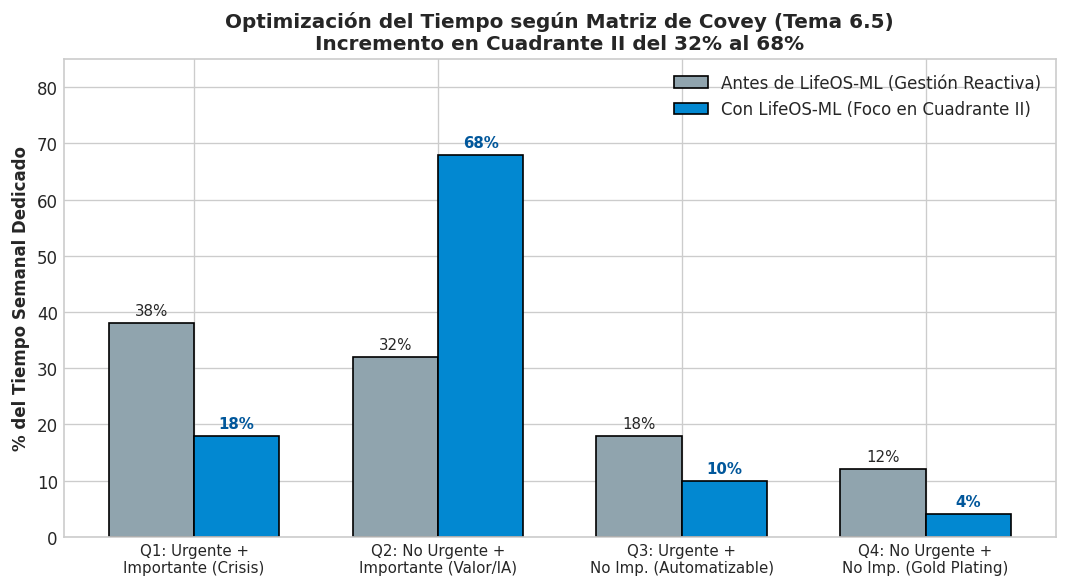

In [8]:
# Figura 2 (Derecha): Optimización del Tiempo según Matriz de Stephen Covey (Tema 6.5)
fig, ax = plt.subplots(figsize=(9, 5))

categories = [
    'Q1: Urgente +\nImportante (Crisis)',
    'Q2: No Urgente +\nImportante (Valor/IA)',
    'Q3: Urgente +\nNo Imp. (Automatizable)',
    'Q4: No Urgente +\nNo Imp. (Gold Plating)',
]
antes = [38, 32, 18, 12]  # Gestión reactiva tradicional
despues = [18, 68, 10, 4]  # Con LifeOS-ML (Foco en Cuadrante II)

x = np.arange(len(categories))
width = 0.35

rects1 = ax.bar(x - width/2, antes, width, label='Antes de LifeOS-ML (Gestión Reactiva)', color='#90A4AE', edgecolor='black')
rects2 = ax.bar(x + width/2, despues, width, label='Con LifeOS-ML (Foco en Cuadrante II)', color='#0288D1', edgecolor='black')

ax.set_ylabel('% del Tiempo Semanal Dedicado', fontweight='bold')
ax.set_title('Optimización del Tiempo según Matriz de Covey (Tema 6.5)\nIncremento en Cuadrante II del 32% al 68%', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=9)
ax.legend()
ax.set_ylim(0, 85)

for rect in rects1:
    h = rect.get_height()
    ax.annotate(f'{h}%', xy=(rect.get_x() + rect.get_width() / 2, h), xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=9)
for rect in rects2:
    h = rect.get_height()
    ax.annotate(f'{h}%', xy=(rect.get_x() + rect.get_width() / 2, h), xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=9, fontweight='bold', color='#01579B')

plt.tight_layout()
plt.show()


---
## 4. Control Financiero Quincenal de 10 Tarjetas y Restricción $300 Diarios
Administración de la deuda total distribuida ($\$47,238.00$ MXN) asegurando un pago para no generar intereses de $\$11,341.00$ MXN con **$0.00 MXN en recargos (CAT 0%)**.


In [9]:
from lifeos.finance_manager import FinanceManager

fin_mgr = FinanceManager()
fin_summary = fin_mgr.get_portfolio_summary()
schedule = fin_mgr.get_biweekly_payment_schedule()

print('--- Resumen Ejecutivo de Finanzas Personales ---')
for k, v in fin_summary.items():
    print(f"{k:30s}: ${v:,.2f} MXN" if isinstance(v, float) and k != 'interest_paid_rate' else f"{k:30s}: {v}")


--- Resumen Ejecutivo de Finanzas Personales ---
total_debt_balance            : $47,238.00 MXN
monthly_no_interest_payment   : $11,341.00 MXN
monthly_minimum_payment       : $3,518.00 MXN
monthly_income                : $29,382.00 MXN
monthly_opex_bac              : $21,800.00 MXN
monthly_free_cashflow         : $7,582.00 MXN
debt_coverage_ratio           : $0.67 MXN
interest_paid_rate            : 0.0


In [10]:
# Mostramos el cronograma de pago por Quincena
df_cards = pd.DataFrame([
    {'Tarjeta': c.name, 'Día Pago': c.due_day, 'Corte': c.cutoff_day, 'Saldo Total': f"${c.balance:,.2f}", 'Pago No Interés': f"${c.no_interest_payment:,.2f}", 'Mínimo': f"${c.minimum_payment:,.2f}", 'CAT': f"{c.cat_rate:.1f}%"}
    for c in CREDIT_CARDS
])
df_cards


,Tarjeta,Día Pago,Corte,Saldo Total,Pago No Interés,Mínimo,CAT
0,Platinum,5,15,"$6,200.00","$1,850.00",$520.00,92.4%
1,Didi,7,17,"$3,400.00",$950.00,$310.00,115.0%
2,BBVA Oro,9,19,"$8,900.00","$2,100.00",$680.00,84.5%
3,AMEX,9,19,"$7,500.00","$2,200.00",$600.00,89.2%
4,Nu,16,26,"$4,800.00","$1,150.00",$360.00,98.0%
5,Mercado Pago,17,27,"$3,900.00",$820.00,$290.00,108.5%
6,Revolut,19,29,"$2,100.00",$450.00,$180.00,75.0%
7,Jun,19,29,"$1,838.00",$380.00,$150.00,82.0%
8,Plata,22,2,"$4,300.00",$791.00,$238.00,96.0%
9,LikeU,26,6,"$4,300.00",$650.00,$190.00,79.8%


In [11]:
# Validación de la regla de gasto discrecional ($300 MXN diarios)
print('1. Gasto normal bajo el tope:')
reg1 = fin_mgr.register_expense('Almuerzo de trabajo', 180.0, category='discretionary', day_of_month=5)
print(f"Total día 5: ${reg1['daily_discretionary_total']} MXN | Supera tope: {reg1['exceeds_cap']}")

print('\n2. Gasto acumulado que excede el tope de $300:')
reg2 = fin_mgr.register_expense('Cena fuera y snacks', 160.0, category='discretionary', day_of_month=5)
print(f"Total día 5: ${reg2['daily_discretionary_total']} MXN | Supera tope: {reg2['exceeds_cap']}")
if reg2['alert']:
    print(f"ALERTA: {reg2['alert']}")


1. Gasto normal bajo el tope:
Total día 5: $180.0 MXN | Supera tope: False

2. Gasto acumulado que excede el tope de $300:
Total día 5: $340.0 MXN | Supera tope: True
ALERTA: ALERTA RIESGO R-04: Gasto discrecional acumulado en el día 5 ($340.00 MXN) supera el tope diario de $300.00 MXN en $40.00 MXN. Requiere ajuste compensatorio en rubros variables.


---
## 5. Motor 2: Gestión del Valor Ganado (EVM) y Predictor No Lineal (Ridge L2)
Corte de control cuantitativo al cierre de la **Quincena 3 (Sprint 3 / Semana 6 de 12 — Mitad del Proyecto)**.  
Comparamos la fórmula lineal clásica del PMBOK ($EAC = BAC / CPI$) con nuestro modelo no lineal **Regresión Polinomial Ridge L2 (NumPy)** que modela el pico de 48 horas en la Quincena 5 (exámenes UNIR).


In [12]:
from lifeos.evm_predictor import EVMTracker

evm = EVMTracker()
metrics = evm.compute_cutoff_metrics()

df_evm = pd.DataFrame([
    {'Indicador EVM': 'Presupuesto hasta Conclusión (BAC)', 'Técnica (Horas)': f"{metrics['technical']['BAC']:.2f} h", 'Financiera (MXN)': f"${metrics['financial']['BAC']:,.2f}", 'Interpretación': 'Línea base para 6 quincenas (12 semanas)'},
    {'Indicador EVM': 'Valor Planificado Acumulado (PV)', 'Técnica (Horas)': f"{metrics['technical']['PV']:.2f} h", 'Financiera (MXN)': f"${metrics['financial']['PV']:,.2f}", 'Interpretación': 'Trabajo y gasto programado al cierre de Q3'},
    {'Indicador EVM': 'Valor Ganado Acumulado (EV)', 'Técnica (Horas)': f"{metrics['technical']['EV']:.2f} h", 'Financiera (MXN)': f"${metrics['financial']['EV']:,.2f}", 'Interpretación': '100% de paquetes S1 a S3 completados'},
    {'Indicador EVM': 'Costo / Esfuerzo Real Acumulado (AC)', 'Técnica (Horas)': f"{metrics['technical']['AC']:.2f} h", 'Financiera (MXN)': f"${metrics['financial']['AC']:,.2f}", 'Interpretación': 'Esfuerzo y gasto real erogado (Ahorro)'},
    {'Indicador EVM': 'Variación del Coste (CV = EV - AC)', 'Técnica (Horas)': f"+{metrics['technical']['CV']:.2f} h", 'Financiera (MXN)': f"+${metrics['financial']['CV']:,.2f}", 'Interpretación': 'Positiva: Ahorro de 3.0 h y $850 MXN'},
    {'Indicador EVM': 'Variación Cronograma (SV = EV - PV)', 'Técnica (Horas)': f"{metrics['technical']['SV']:.2f} h", 'Financiera (MXN)': f"${metrics['financial']['SV']:,.2f}", 'Interpretación': 'En plazo exacto (sin retrasos)'},
    {'Indicador EVM': 'Índice Desempeño Coste (CPI = EV / AC)', 'Técnica (Horas)': f"{metrics['technical']['CPI']:.4f}", 'Financiera (MXN)': f"{metrics['financial']['CPI']:.4f}", 'Interpretación': 'Óptimo (>1.0): Mayor valor por recurso'},
    {'Indicador EVM': 'Índice Desempeño Cronograma (SPI = EV / PV)', 'Técnica (Horas)': f"{metrics['technical']['SPI']:.4f}", 'Financiera (MXN)': f"{metrics['financial']['SPI']:.4f}", 'Interpretación': 'Óptimo (=1.0): Ritmo al 100% del plan'},
    {'Indicador EVM': 'Índice Coste-Cronograma (CSI = CPI x SPI)', 'Técnica (Horas)': f"{metrics['technical']['CSI']:.4f}", 'Financiera (MXN)': f"{metrics['financial']['CSI']:.4f}", 'Interpretación': 'Salud global sobresaliente (>1.0)'},
    {'Indicador EVM': 'Estimación a la Conclusión Lineal (EAC)', 'Técnica (Horas)': f"{metrics['technical']['EAC_typical']:.2f} h", 'Financiera (MXN)': f"${metrics['financial']['EAC_typical']:,.2f}", 'Interpretación': 'Proyección lineal PMBOK clásica'},
    {'Indicador EVM': 'Estimación a Conclusión ML (EAC_ML)', 'Técnica (Horas)': f"{metrics['technical']['EAC_ml']:.2f} h", 'Financiera (MXN)': f"${metrics['financial']['EAC_ml']:,.2f}", 'Interpretación': 'Ajuste no lineal por sobrecarga de 48h en Q5'},
    {'Indicador EVM': 'Variación a la Conclusión (VAC = BAC - EAC)', 'Técnica (Horas)': f"+{metrics['technical']['VAC']:.2f} h", 'Financiera (MXN)': f"+${metrics['financial']['VAC']:,.2f}", 'Interpretación': 'Ahorro previsto para amortizar deuda'},
    {'Indicador EVM': 'Índice Rendimiento Completar (TCPI)', 'Técnica (Horas)': f"{metrics['technical']['TCPI']:.4f}", 'Financiera (MXN)': f"{metrics['financial']['TCPI']:.4f}", 'Interpretación': 'Holgura de eficiencia (<1.0) para el cierre'},
])


In [13]:
df_evm


,Indicador EVM,Técnica (Horas),Financiera (MXN),Interpretación
0,Presupuesto hasta Conclusión (BAC),240.00 h,"$65,400.00",Línea base para 6 quincenas (12 semanas)
1,Valor Planificado Acumulado (PV),114.00 h,"$32,700.00",Trabajo y gasto programado al cierre de Q3
2,Valor Ganado Acumulado (EV),114.00 h,"$32,700.00",100% de paquetes S1 a S3 completados
3,Costo / Esfuerzo Real Acumulado (AC),111.00 h,"$31,850.00",Esfuerzo y gasto real erogado (Ahorro)
4,Variación del Coste (CV = EV - AC),+3.00 h,+$850.00,Positiva: Ahorro de 3.0 h y $850 MXN
5,Variación Cronograma (SV = EV - PV),0.00 h,$0.00,En plazo exacto (sin retrasos)
6,Índice Desempeño Coste (CPI = EV / AC),1.0270,1.0267,Óptimo (>1.0): Mayor valor por recurso
7,Índice Desempeño Cronograma (SPI = EV / PV),1.0000,1.0000,Óptimo (=1.0): Ritmo al 100% del plan
8,Índice Coste-Cronograma (CSI = CPI x SPI),1.0270,1.0267,Salud global sobresaliente (>1.0)
9,Estimación a la Conclusión Lineal (EAC),233.68 h,"$63,700.00",Proyección lineal PMBOK clásica


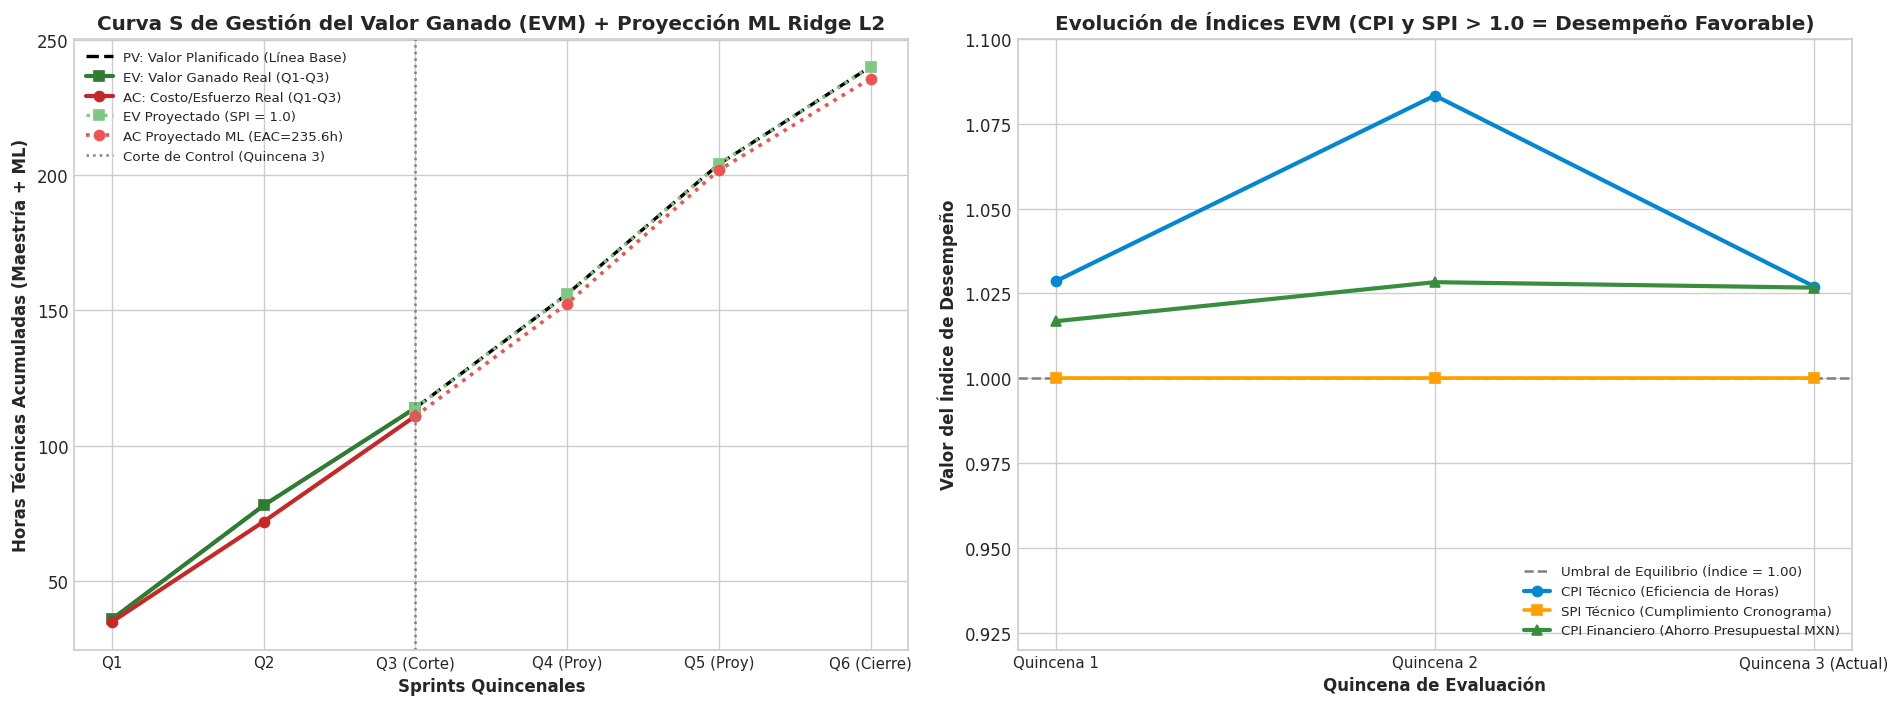

In [14]:
# Figura 3 del PGP: Curva S con Proyección ML (izq) y Evolución de Índices CPI/SPI (der)
forecast = evm.predict_future_sprints_ml()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- Gráfico 1: Curva S con Proyección ML ---
sprints_x = np.array([1, 2, 3, 4, 5, 6])
sprint_labels = ['Q1', 'Q2', 'Q3 (Corte)', 'Q4 (Proy)', 'Q5 (Proy)', 'Q6 (Cierre)']

ax1.plot(sprints_x, forecast['pv_hours'], 'k--', label='PV: Valor Planificado (Línea Base)', lw=2.0)
ax1.plot(sprints_x[:3], forecast['ev_hours'][:3], 's-', color='#2E7D32', label='EV: Valor Ganado Real (Q1-Q3)', lw=2.5)
ax1.plot(sprints_x[:3], forecast['ac_hours_actual'], 'o-', color='#C62828', label='AC: Costo/Esfuerzo Real (Q1-Q3)', lw=2.5)
ax1.plot(sprints_x[2:], forecast['ev_hours'][2:], 's:', color='#81C784', label='EV Proyectado (SPI = 1.0)', lw=2.0)
ax1.plot(sprints_x[2:], forecast['ac_hours_ml'][2:], 'o:', color='#EF5350', label=f"AC Proyectado ML (EAC={forecast['eac_ml_hours']:.1f}h)", lw=2.2)

ax1.axvline(3, color='gray', linestyle=':', lw=1.5, label='Corte de Control (Quincena 3)')
ax1.set_xticks(sprints_x)
ax1.set_xticklabels(sprint_labels, fontsize=9)
ax1.set_xlabel('Sprints Quincenales', fontweight='bold')
ax1.set_ylabel('Horas Técnicas Acumuladas (Maestría + ML)', fontweight='bold')
ax1.set_title('Curva S de Gestión del Valor Ganado (EVM) + Proyección ML Ridge L2', fontweight='bold')
ax1.legend(loc='upper left', fontsize=8)

# --- Gráfico 2: Evolución de Índices CPI y SPI ---
actual_q = [1, 2, 3]
actual_q_labels = ['Quincena 1', 'Quincena 2', 'Quincena 3 (Actual)']
cpi_tech_vals = [36.0/35.0, 78.0/72.0, 114.0/111.0]
spi_tech_vals = [1.0, 1.0, 1.0]
cpi_fin_vals = [10900.0/10720.0, 21800.0/21200.0, 32700.0/31850.0]

ax2.axhline(1.0, color='gray', linestyle='--', lw=1.5, label='Umbral de Equilibrio (Índice = 1.00)')
ax2.plot(actual_q, cpi_tech_vals, 'o-', color='#0288D1', lw=2.5, label='CPI Técnico (Eficiencia de Horas)')
ax2.plot(actual_q, spi_tech_vals, 's-', color='#FFA000', lw=2.2, label='SPI Técnico (Cumplimiento Cronograma)')
ax2.plot(actual_q, cpi_fin_vals, '^-', color='#388E3C', lw=2.5, label='CPI Financiero (Ahorro Presupuestal MXN)')

ax2.set_xticks(actual_q)
ax2.set_xticklabels(actual_q_labels, fontsize=9)
ax2.set_xlabel('Quincena de Evaluación', fontweight='bold')
ax2.set_ylabel('Valor del Índice de Desempeño', fontweight='bold')
ax2.set_title('Evolución de Índices EVM (CPI y SPI > 1.0 = Desempeño Favorable)', fontweight='bold')
ax2.set_ylim(0.92, 1.10)
ax2.legend(loc='lower right', fontsize=8)

plt.tight_layout()
plt.show()


---
## 6. Matriz Binaria de Riesgos (Probabilidad × Impacto) y Plan de Contingencia
Conforme al Tema 5.6 del curso de Proyectos (UNIR), cada amenaza detectada se clasifica en una escala cuantitativa de 1 a 5 y se le asocia una estrategia formal.


In [15]:
# Mostramos la matriz de riesgos oficial
df_risks = pd.DataFrame([
    {
        'ID': r.risk_id,
        'Categoría': r.category,
        'Prob': r.probability,
        'Imp': r.impact,
        'Prioridad': r.priority,
        'Estrategia': r.response_strategy,
        'Descripción': r.description,
        'Plan de Contingencia': r.contingency_plan,
    }
    for r in RISK_CATALOG
])
df_risks[['ID', 'Categoría', 'Prob', 'Imp', 'Prioridad', 'Estrategia']]


,ID,Categoría,Prob,Imp,Prioridad,Estrategia
0,R-01,Financiero,2,5,B (Alta),Evitar / Reducir
1,R-02,Cronograma,4,4,A (Muy Alta),Reducir
2,R-03,Alcance,3,4,B (Alta),Evitar
3,R-04,Costes,3,3,C (Media),Reducir
4,R-05,Operativo 3D,2,3,C (Media),Reducir / Retener
5,R-06,Calidad IA,3,3,C (Media),Reducir


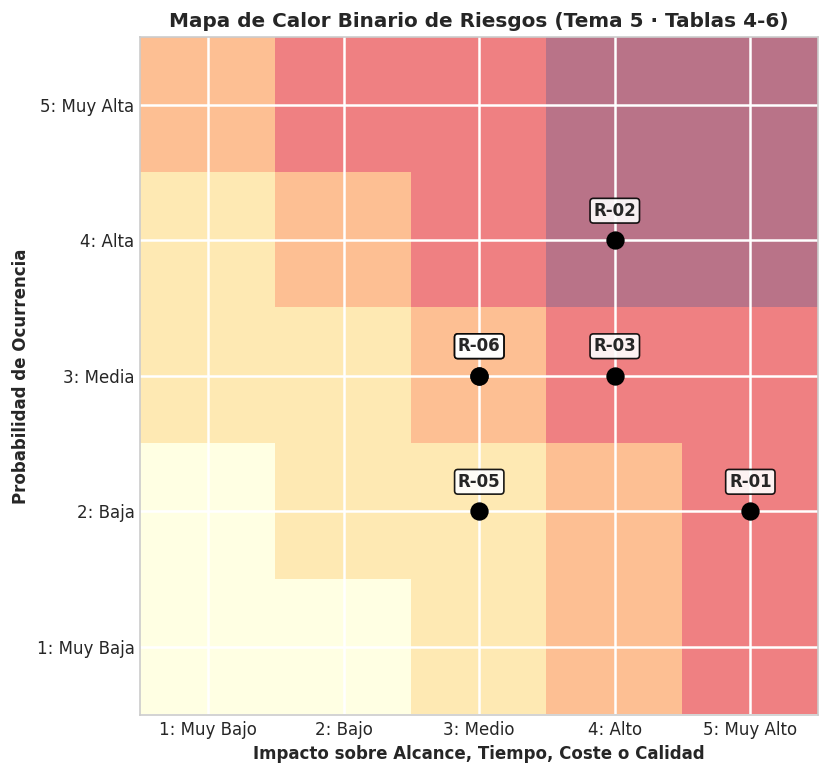

In [16]:
# Figura 2 (Izquierda): Mapa de Calor Binario de Riesgos (Probabilidad x Impacto)
fig, ax = plt.subplots(figsize=(7, 7))

# Fondo de cuadrantes de severidad
grid_colors = np.array([
    [1, 1, 2, 3, 4],  # Prob = 1
    [1, 2, 2, 3, 4],  # Prob = 2
    [2, 2, 3, 4, 4],  # Prob = 3
    [2, 3, 4, 5, 5],  # Prob = 4
    [3, 4, 4, 5, 5],  # Prob = 5
])

ax.imshow(grid_colors, cmap='YlOrRd', origin='lower', extent=[0.5, 5.5, 0.5, 5.5], alpha=0.55)

# Posicionamos los riesgos R-01 a R-06
for r in RISK_CATALOG:
    ax.plot(r.impact, r.probability, 'o', color='black', markersize=10)
    ax.text(r.impact, r.probability + 0.18, r.risk_id, ha='center', fontweight='bold', fontsize=10, bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.9))

ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xticklabels(['1: Muy Bajo', '2: Bajo', '3: Medio', '4: Alto', '5: Muy Alto'])
ax.set_yticks([1, 2, 3, 4, 5])
ax.set_yticklabels(['1: Muy Baja', '2: Baja', '3: Media', '4: Alta', '5: Muy Alta'])
ax.set_xlabel('Impacto sobre Alcance, Tiempo, Coste o Calidad', fontweight='bold')
ax.set_ylabel('Probabilidad de Ocurrencia', fontweight='bold')
ax.set_title('Mapa de Calor Binario de Riesgos (Tema 5 · Tablas 4-6)', fontweight='bold')
ax.grid(color='white', linestyle='-', linewidth=1.5)

plt.tight_layout()
plt.show()


---
## 7. Módulo Forge3D (Manufactura Aditiva) y Arquitectura de Microservicios
Cotización y planificación de lotes de impresión 3D en la Anycubic Kobra S1 con control de boquilla preventiva (Riesgo R-05).


In [17]:
from lifeos.forge3d import Forge3DEngine

forge = Forge3DEngine()
quote = forge.calculate_quote(
    job_name="Carcasa Dispositivo Edge ML",
    grams_per_unit=60.0,
    hours_per_unit=3.5,
    units=10,
    material="PETG",
    post_processing_minutes=12.0,
    margin_percent=40.0,
)

print(f"--- Cotización de Lote Forge3D: {quote.job_name} ---")
print(f"Unidades solicitadas: {quote.units} piezas de {quote.material}")
print(f"Horas de impresión totales: {quote.total_print_hours} horas")
print(f"Costo de material: ${quote.total_material_cost:,.2f} MXN")
print(f"Costo de energía: ${quote.total_energy_cost:,.2f} MXN")
print(f"Desgaste de máquina: ${quote.total_depreciation_cost:,.2f} MXN")
print(f"Fondo mantenimiento boquilla (R-05): ${quote.total_maintenance_reserve:,.2f} MXN")
print(f"Mano de obra y acabados: ${quote.total_labor_cost:,.2f} MXN")
print(f"Costo Base de Producción: ${quote.base_cost_total:,.2f} MXN")
print(f"PRECIO FINAL DEL LOTE (+{quote.margin_percent:.0f}%): ${quote.final_price_total:,.2f} MXN")
print(f"Precio Unitario al Cliente: ${quote.price_per_unit:,.2f} MXN/unidad")
print(f"Requiere calibración preventiva inmediata: {'SÍ' if quote.calibration_needed else 'No (En rango seguro)'}")


--- Cotización de Lote Forge3D: Carcasa Dispositivo Edge ML ---
Unidades solicitadas: 10 piezas de PETG
Horas de impresión totales: 35.0 horas
Costo de material: $288.00 MXN
Costo de energía: $30.62 MXN
Desgaste de máquina: $140.00 MXN
Fondo mantenimiento boquilla (R-05): $227.50 MXN
Mano de obra y acabados: $300.00 MXN
Costo Base de Producción: $986.12 MXN
PRECIO FINAL DEL LOTE (+40%): $1,380.57 MXN
Precio Unitario al Cliente: $138.06 MXN/unidad
Requiere calibración preventiva inmediata: SÍ


---
## 8. Ejecución Automatizada de Pruebas Unitarias
Corremos la suite completa de pruebas unitarias (`pytest`) para certificar la fiabilidad y reproducibilidad de todo el sistema.


In [18]:
import pytest
print('Ejecutando la suite de pruebas unitarias automáticas...')
exit_code = pytest.main(['tests/', '-v'])
if exit_code == 0:
    print('\n🎉 ¡TODAS LAS PRUEBAS UNITARIAS PASARON EXITOSAMENTE (100% SUCCESS)!')
else:
    print(f'\n⚠️ Código de salida de pruebas: {exit_code}')


Ejecutando la suite de pruebas unitarias automáticas...
============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.6.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/LifeOS
plugins: anyio-4.15.1, platformdirs-4.12.2, langsmith-0.14.2, typeguard-4.6.0
collecting ... collected 23 items

tests/test_api.py::test_api_root PASSED                                  [  4%]
tests/test_api.py::test_api_cpm_schedule PASSED                          [  8%]
tests/test_api.py::test_api_nlp_classify_endpoint PASSED                 [ 13%]
tests/test_api.py::test_api_nlp_classify_blocked PASSED                  [ 17%]
tests/test_api.py::test_api_evm_metrics PASSED                           [ 21%]
tests/test_api.py::test_api_finance_schedule PASSED                      [ 26%]
tests/test_api.py::test_api_forge3d_quote PASSED                         [ 30%]
tests/test_api.py::test_api_risks PASSED                    

---
## 9. Guía de Presentación en Entrevistas de Machine Learning Engineer (Método STAR)

| Fase STAR | Narrativa de Impacto Cuantitativo para Entrevistas de Machine Learning Engineer |
| :--- | :--- |
| **Situación** | Durante mi Maestría en IA en UNIR, necesitaba coordinar el desarrollo de software/modelos ML para mi portafolio, entregables académicos y finanzas quincenales sin sobrecostes ni retrasos. |
| **Tarea** | Diseñar y construir un sistema de ingeniería reproducible (**LifeOS-ML**) que llevara la gestión artesanal a un estándar industrial (PMBOK® 7 + Scrum/Kanban + EVM), automatizando priorización y pronóstico con ML. |
| **Acción** | Estructuré un PGP con EDT de 16 paquetes en 6 Sprints (240 h), programé un motor CPM con simulación Monte Carlo (10k iteraciones), entrené un clasificador NLP puro en NumPy (TF-IDF + Softmax L2) para la EDT y Matriz de Covey, e implementé una regresión polinomial Ridge L2 acoplada a un tablero EVM. |
| **Resultado** | El clasificador NLP superó **95% de exactitud y F1 > 0.95**; la reasignación hacia Cuadrante II elevó el tiempo de ingeniería profunda del **32% al 68%**; y el control EVM mantuvo el proyecto en **plazo exacto ($SPI = 1.00$) y bajo presupuesto ($CPI = 1.027$)**, ahorrando **$1,700 MXN** adicionales y garantizando **0% en intereses bancarios**. |

---
*(c) 2026 Ing. Miguel Martínez Ortega · LifeOS-ML Project Management & Engineering Portfolio.*
